In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Load the dataset
df = pd.read_csv(r"C:\Users\Admin\Desktop\housing.csv")

# Verify the data structure
df.head()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [ ]:
df.describe()

In [3]:
# Inspecting Datasset for missing values

print("="*60)
print("STEP 1: INSPECTING DATASET FOR MISSING (NULL) VALUES")
print("="*60)

# Calculating total and percentage of missing values per column
null_counts = df.isnull().sum()
null_percentages = (df.isnull().sum() / len(df)) * 100

null_inspection_df = pd.DataFrame({
    'Missing Values (Count)': null_counts,
    'Missing Values (%)': null_percentages
})

# Display summary for columns with missing data
print(null_inspection_df[null_inspection_df['Missing Values (Count)'] > 0])
print(f"\nTotal rows containing missing data: {df.isnull().any(axis=1).sum()} out of {len(df)} total rows.\n")

print("="*60)
print("STEP 2: IMPUTATION AND FEATURE ENGINEERING")
print("="*60)

# Impute null values with the column median found during inspection
total_bedrooms_median = df['total_bedrooms'].median()
df['total_bedrooms'] = df['total_bedrooms'].fillna(total_bedrooms_median)

# Double checking that nulls are completely resolved
print(f"Post-imputation null values remaining in dataset: {df.isnull().sum().sum()}")

# Feature Engineering: Creating interaction attributes to handle multicollinearity and maximize signal
df['rooms_per_household'] = df['total_rooms'] / df['households']
df['bedrooms_per_room'] = df['total_bedrooms'] / df['total_rooms']
df['population_per_household'] = df['population'] / df['households']

print("Interaction features successfully engineered!")


STEP 1: INSPECTING DATASET FOR MISSING (NULL) VALUES
                Missing Values (Count)  Missing Values (%)
total_bedrooms                     207            1.002907

Total rows containing missing data: 207 out of 20640 total rows.

STEP 2: IMPUTATION AND FEATURE ENGINEERING
Post-imputation null values remaining in dataset: 0
Interaction features successfully engineered!


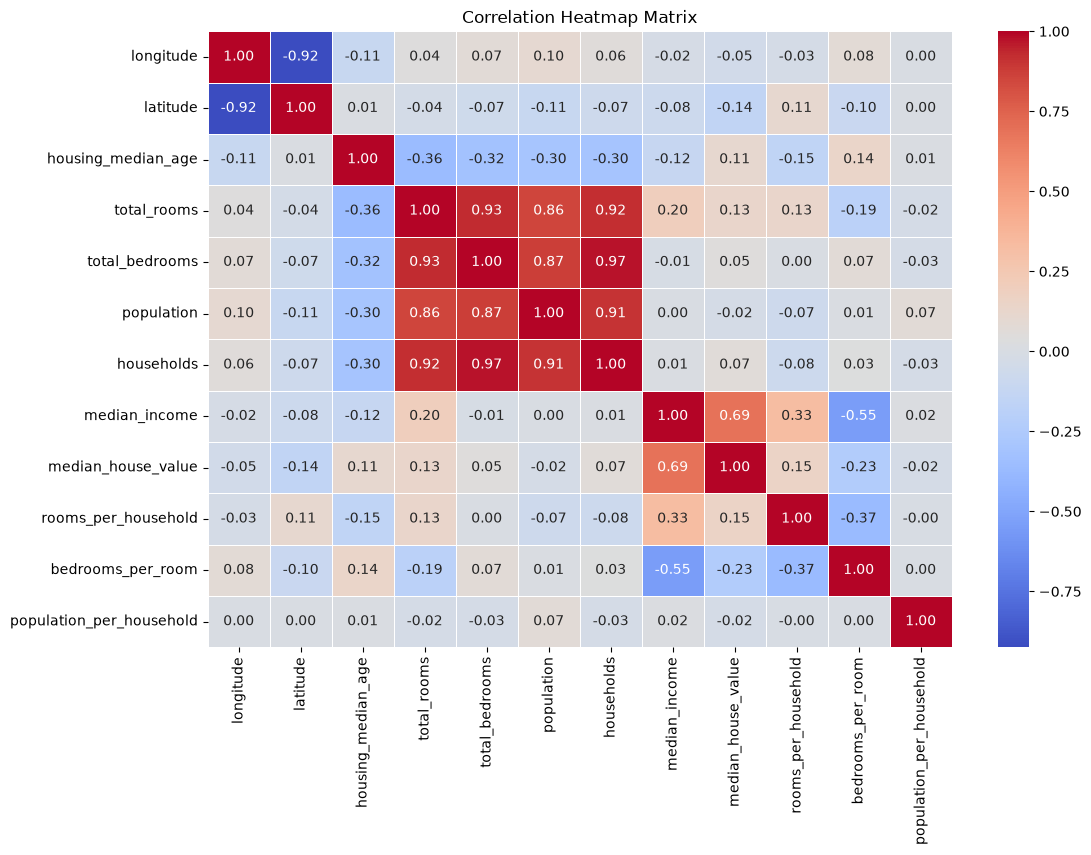

In [4]:
# Isolating numerical columns to compute correlations safely
numeric_df = df.drop(columns=['ocean_proximity'])

# Generate the correlation heatmap matrix
plt.figure(figsize=(12, 8))
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Heatmap Matrix")
plt.show()


In [5]:
# Categorical encoding using One-Hot Encoding
df_encoded = pd.get_dummies(df, columns=['ocean_proximity'], drop_first=True)

# Separate features (X) and target variable (y)
X = df_encoded.drop(columns=['median_house_value'])
y = df_encoded['median_house_value']

# Perform train/test dataset splitting (80/20 split as requested)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

# Standardize features using StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data fully encoded, split, and standardized.")


Data fully encoded, split, and standardized.


In [6]:
# Train Ordinary Least Squares (OLS) Linear Regression
ols_model = LinearRegression()
ols_model.fit(X_train_scaled, y_train)
ols_preds = ols_model.predict(X_test_scaled)

# Define alpha search parameters for regularized models
param_grid = {'alpha': [0.1, 1.0, 10.0, 100.0]}

# GridSearch for Ridge Regression
ridge_grid = GridSearchCV(Ridge(), param_grid, cv=5, scoring='neg_mean_squared_error')
ridge_grid.fit(X_train_scaled, y_train)
best_ridge = ridge_grid.best_estimator_
ridge_preds = best_ridge.predict(X_test_scaled)

# GridSearch for Lasso Regression
lasso_grid = GridSearchCV(Lasso(max_iter=10000), param_grid, cv=5, scoring='neg_mean_squared_error')
lasso_grid.fit(X_train_scaled, y_train)
best_lasso = lasso_grid.best_estimator_
lasso_preds = best_lasso.predict(X_test_scaled)

print(f"Optimal Ridge Alpha: {ridge_grid.best_params_['alpha']}")
print(f"Optimal Lasso Alpha: {lasso_grid.best_params_['alpha']}")


Optimal Ridge Alpha: 10.0
Optimal Lasso Alpha: 100.0


In [7]:
def compute_metrics(y_true, y_pred, model_name):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return {'Model': model_name, 'RMSE': rmse, 'MAE': mae, 'R2': r2}

# Collate results into a benchmark data summary matrix
results = [
    compute_metrics(y_test, ols_preds, "OLS Linear Regression"),
    compute_metrics(y_test, ridge_preds, f"Ridge (Alpha: {ridge_grid.best_params_['alpha']})"),
    compute_metrics(y_test, lasso_preds, f"Lasso (Alpha: {lasso_grid.best_params_['alpha']})")
]

results_df = pd.DataFrame(results)
print("="*60)
print("REGRESSION MODEL BENCHMARK PERFORMANCE METRICS")
print("="*60)
print(results_df.to_string(index=False))


REGRESSION MODEL BENCHMARK PERFORMANCE METRICS
                Model         RMSE          MAE       R2
OLS Linear Regression 72668.538379 50888.660016 0.597018
  Ridge (Alpha: 10.0) 72647.548089 50885.562000 0.597250
 Lasso (Alpha: 100.0) 72522.078914 50832.253635 0.598640


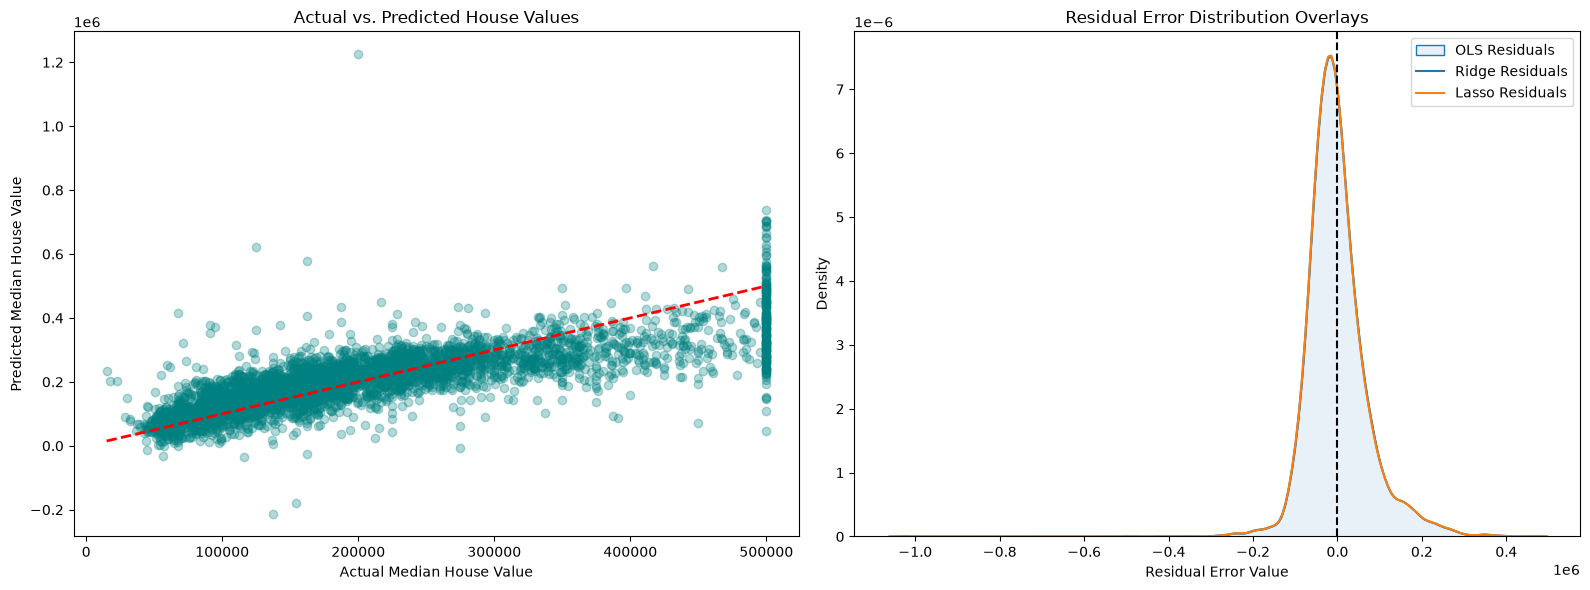

In [8]:
# 7. Visual plots setup (Corrected to index the axes array)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Actual vs Predicted Scatter Chart (Drawn on the 1st subplot: axes[0])
axes[0].scatter(y_test, ols_preds, alpha=0.3, color='teal')
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
axes[0].set_title('Actual vs. Predicted House Values')
axes[0].set_xlabel('Actual Median House Value')
axes[0].set_ylabel('Predicted Median House Value')

# Plot 2: Residual Error Distribution Curves (Drawn on the 2nd subplot: axes[1])
residuals_ols = y_test - ols_preds
residuals_ridge = y_test - ridge_preds
residuals_lasso = y_test - lasso_preds

# We pass ax=axes[1] to place these distributions on the right hand side
sns.kdeplot(residuals_ols, label='OLS Residuals', ax=axes[1], fill=True, alpha=0.1)
sns.kdeplot(residuals_ridge, label='Ridge Residuals', ax=axes[1])
sns.kdeplot(residuals_lasso, label='Lasso Residuals', ax=axes[1])
axes[1].axvline(0, color='black', linestyle='--')
axes[1].set_title('Residual Error Distribution Overlays')
axes[1].set_xlabel('Residual Error Value')
axes[1].legend()

plt.tight_layout()
plt.show()
